In [1]:
import kagglehub
import pandas as pd

# Descarga automática del dataset en Colab
ruta = kagglehub.dataset_download("ericanacletoribeiro/cicids2017-cleaned-and-preprocessed")
df = pd.read_csv(f"{ruta}/cicids2017_cleaned.csv")

print("Filas y columnas:", df.shape)
print(df.iloc[:, -1].value_counts()) # Muestra las clases de ataques

100%|██████████| 200M/200M [00:01<00:00, 199MB/s]

Extracting files...


Filas y columnas: (2520751, 53)
Attack Type
Normal Traffic    2095057
DoS                193745
DDoS               128014
Port Scanning       90694
Brute Force          9150
Web Attacks          2143
Bots                 1948
Name: count, dtype: int64


Preprocesamiento, limpieza final y escalado
Esta celda separa las características (X) de las etiquetas (y), crea la división estratificada de prueba (Test = 20%) y aplica StandardScaler para estabilizar los gradientes.

In [2]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import f1_score, classification_report

# Semilla para reproducibilidad
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

# 1. Limpieza de posibles valores infinitos o nulos
df_clean = df.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()

# 2. Submuestreo balanceado para que entrene rápido sin perder ataques minoritarios
# Tomamos máximo 150,000 filas de tráfico normal y TODOS los ataques
df_normal = df_clean[df_clean["Attack Type"] == "Normal Traffic"].sample(n=150000, random_state=SEED)
df_ataques = df_clean[df_clean["Attack Type"] != "Normal Traffic"]
df_final = pd.concat([df_normal, df_ataques]).sample(frac=1, random_state=SEED).reset_index(drop=True)

# 3. Separar X (características) e y (etiquetas)
X = df_final.drop(columns=["Attack Type"]).values
le = LabelEncoder()
y = le.fit_transform(df_final["Attack Type"].values)
NUM_CLASES = len(le.classes_)
print("Clases codificadas:", dict(enumerate(le.classes_)))

# 4. División Train (80%) y Test global (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# 5. Escalado (fit SOLO en train para evitar fuga de datos)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")

Usando dispositivo: cuda
Clases codificadas: {0: 'Bots', 1: 'Brute Force', 2: 'DDoS', 3: 'DoS', 4: 'Normal Traffic', 5: 'Port Scanning', 6: 'Web Attacks'}
Train shape: (460555, 52) | Test shape: (115139, 52)


particionamiento en 5 nodos. Aquí creamos las particiones que simulan las 5 organizaciones distintas con distribución heterogénea ($\alpha = 0.3$).

In [3]:
NUM_NODOS = 5

def particionar_iid(X, y, num_nodos=5):
    indices = np.random.permutation(len(X))
    splits = np.array_split(indices, num_nodos)
    return [(X[idx], y[idx]) for idx in splits]

def particionar_dirichlet(X, y, num_nodos=5, alpha=0.3):
    """Reparte cada clase de ataque de forma desigual entre los 5 nodos"""
    nodos_idx = [[] for _ in range(num_nodos)]
    for c in range(NUM_CLASES):
        idx_c = np.where(y == c)[0]
        np.random.shuffle(idx_c)
        proporciones = np.random.dirichlet(np.repeat(alpha, num_nodos))
        puntos_corte = (np.cumsum(proporciones) * len(idx_c)).astype(int)[:-1]
        for nodo_id, split in enumerate(np.split(idx_c, puntos_corte)):
            nodos_idx[nodo_id].extend(split)
    return [(X[idx], y[idx]) for idx in nodos_idx]

nodos_iid = particionar_iid(X_train, y_train, NUM_NODOS)
nodos_noiid = particionar_dirichlet(X_train, y_train, NUM_NODOS, alpha=0.3)

for i, (_, y_n) in enumerate(nodos_noiid):
    conteo = {le.classes_[k]: int((y_n == k).sum()) for k in range(NUM_CLASES)}
    print(f"Nodo {i+1} (No-IID): {conteo}")

Nodo 1 (No-IID): {'Bots': 305, 'Brute Force': 0, 'DDoS': 0, 'DoS': 37729, 'Normal Traffic': 24880, 'Port Scanning': 923, 'Web Attacks': 59}
Nodo 2 (No-IID): {'Bots': 0, 'Brute Force': 2054, 'DDoS': 11815, 'DoS': 5517, 'Normal Traffic': 1142, 'Port Scanning': 11574, 'Web Attacks': 33}
Nodo 3 (No-IID): {'Bots': 152, 'Brute Force': 66, 'DDoS': 536, 'DoS': 11985, 'Normal Traffic': 39847, 'Port Scanning': 41121, 'Web Attacks': 423}
Nodo 4 (No-IID): {'Bots': 1101, 'Brute Force': 2, 'DDoS': 86463, 'DoS': 97136, 'Normal Traffic': 39522, 'Port Scanning': 17935, 'Web Attacks': 346}
Nodo 5 (No-IID): {'Bots': 1, 'Brute Force': 5198, 'DDoS': 3597, 'DoS': 2629, 'Normal Traffic': 14609, 'Port Scanning': 1002, 'Web Attacks': 853}


Definición del Modelo MLP y Entrenamiento de Baselines (Centralizado vs. Aislados)
Esta celda entrena el Modelo Centralizado (techo teórico) y los 5 Modelos Aislados (línea base inferior), dándote las primeras métricas reales para tus gráficas y tablas.

In [4]:
class DetectorMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        return self.net(x)

def entrenar_modelo(X_tr, y_tr, epochs=10, batch_size=512, lr=1e-3):
    modelo = DetectorMLP(X_tr.shape[1], NUM_CLASES).to(device)
    criterio = nn.CrossEntropyLoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)

    ds = TensorDataset(torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.long))
    loader = DataLoader(ds, batch_size=batch_size, shuffle=True)

    modelo.train()
    for ep in range(epochs):
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            optimizador.zero_grad()
            out = modelo(bx)
            loss = criterio(out, by)
            loss.backward()
            optimizador.step()
    return modelo

def evaluar_f1(modelo, X_te, y_te):
    modelo.eval()
    with torch.no_grad():
        logits = modelo(torch.tensor(X_te, dtype=torch.float32).to(device))
        preds = logits.argmax(dim=1).cpu().numpy()
    return f1_score(y_te, preds, average="macro")

# 1. Baseline Centralizado (todos los datos juntos)
modelo_central = entrenar_modelo(X_train, y_train, epochs=12)
f1_central = evaluar_f1(modelo_central, X_test, y_test)
print(f"\n>>> F1-Macro CENTRALIZADO (Techo teórico): {f1_central:.4f}")

# 2. Baselines Aislados (cada nodo entrena solo con lo suyo en escenario No-IID)
f1_aislados = []
for i, (Xn, yn) in enumerate(nodos_noiid):
    m_aislado = entrenar_modelo(Xn, yn, epochs=12)
    f1 = evaluar_f1(m_aislado, X_test, y_test)
    f1_aislados.append(f1)
    print(f"Nodo {i+1} AISLADO -> F1-Macro en test global: {f1:.4f}")

print(f"\n>>> Promedio F1-Macro NODOS AISLADOS: {np.mean(f1_aislados):.4f}")


>>> F1-Macro CENTRALIZADO (Techo teórico): 0.9297
Nodo 1 AISLADO -> F1-Macro en test global: 0.3648
Nodo 2 AISLADO -> F1-Macro en test global: 0.6144
Nodo 3 AISLADO -> F1-Macro en test global: 0.6572
Nodo 4 AISLADO -> F1-Macro en test global: 0.7821
Nodo 5 AISLADO -> F1-Macro en test global: 0.7625

>>> Promedio F1-Macro NODOS AISLADOS: 0.6362


Instalación de Flower y Configuración de Clientes Federados

In [5]:
!pip install -q "flwr[simulation]"

import flwr as fl
from collections import OrderedDict

def get_weights(net):
    return [val.cpu().numpy() for _, val in net.state_dict().items()]

def set_weights(net, parameters):
    params_dict = zip(net.state_dict().keys(), parameters)
    state_dict = OrderedDict({k: torch.tensor(v) for k, v in params_dict})
    net.load_state_dict(state_dict, strict=True)

class NodoCliente(fl.client.NumPyClient):
    def __init__(self, X_local, y_local, mu=0.0):
        self.net = DetectorMLP(X_local.shape[1], NUM_CLASES).to(device)
        self.X_local = X_local
        self.y_local = y_local
        self.mu = mu  # mu > 0 activa la regularización proximal de FedProx

    def get_parameters(self, config):
        return get_weights(self.net)

    def fit(self, parameters, config):
        set_weights(self.net, parameters)
        global_params = [p.clone().detach() for p in self.net.parameters()]

        criterio = nn.CrossEntropyLoss()
        optimizador = torch.optim.Adam(self.net.parameters(), lr=1e-3)
        ds = TensorDataset(torch.tensor(self.X_local, dtype=torch.float32), torch.tensor(self.y_local, dtype=torch.long))
        loader = DataLoader(ds, batch_size=512, shuffle=True)

        self.net.train()
        for _ in range(3):  # 3 épocas locales por ronda federada
            for bx, by in loader:
                bx, by = bx.to(device), by.to(device)
                optimizador.zero_grad()
                loss = criterio(self.net(bx), by)

                # Término proximal de FedProx (penaliza alejarse del modelo global)
                if self.mu > 0:
                    proximal_term = sum(((w - w_g) ** 2).sum() for w, w_g in zip(self.net.parameters(), global_params))
                    loss += (self.mu / 2) * proximal_term

                loss.backward()
                optimizador.step()

        return get_weights(self.net), len(self.X_local), {}

    def evaluate(self, parameters, config):
        set_weights(self.net, parameters)
        f1 = evaluar_f1(self.net, X_test, y_test)
        return 0.0, len(X_test), {"f1_macro": float(f1)}

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
bigframes 2.51.0 requires rich<14,>=12.4.4, but you have rich 14.3.4 which is incompatible.


Ejecución de Experimento E1 (FedAvg) y E2 (FedProx) + Gráfica Comparativa

Ejecutando Experimento E1: FedAvg (No-IID)...


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          


Ejecutando Experimento E2: FedProx (No-IID, mu=0.05)...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-11-18 00:15:57,345	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'memory': 9263458714.0, 'node:__internal_head__': 1.0, 'CPU': 2.0, 'node:172.28.0.12': 1.0, 'GPU': 1.0, 'object_store_memory': 3970053734.0, 'accelerator_type:T4': 1.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 1, 'num_gpus': 0.2}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 2 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(ClientAp

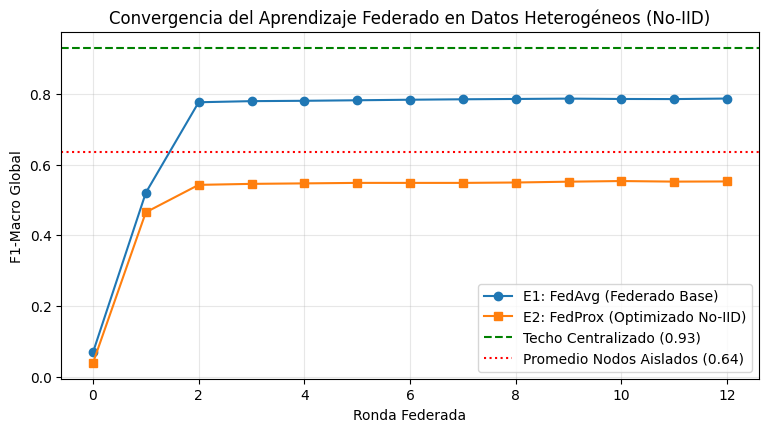

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [6]:
import matplotlib.pyplot as plt

def evaluar_global(server_round, parameters, config):
    modelo_eval = DetectorMLP(X_train.shape[1], NUM_CLASES).to(device)
    set_weights(modelo_eval, parameters)
    f1 = evaluar_f1(modelo_eval, X_test, y_test)
    return 0.0, {"f1_macro": f1}

def correr_federacion(mu=0.0, num_rondas=12):
    def client_fn(cid: str):
        idx = int(cid)
        Xn, yn = nodos_noiid[idx]
        return NodoCliente(Xn, yn, mu=mu).to_client()

    estrategia = fl.server.strategy.FedAvg(
        fraction_fit=1.0,
        fraction_evaluate=0.0,
        min_fit_clients=NUM_NODOS,
        min_available_clients=NUM_NODOS,
        evaluate_fn=evaluar_global,
    )

    hist = fl.simulation.start_simulation(
        client_fn=client_fn,
        num_clients=NUM_NODOS,
        config=fl.server.ServerConfig(num_rounds=num_rondas),
        strategy=estrategia,
        client_resources={"num_cpus": 1, "num_gpus": 0.2},
    )
    return [val for _, val in hist.metrics_centralized["f1_macro"]]

print("Ejecutando Experimento E1: FedAvg (No-IID)...")
f1_fedavg = correr_federacion(mu=0.0, num_rondas=12)

print("\nEjecutando Experimento E2: FedProx (No-IID, mu=0.05)...")
f1_fedprox = correr_federacion(mu=0.05, num_rondas=12)

# Gráfica lista para tu informe y presentación
rondas = range(0, len(f1_fedavg))
plt.figure(figsize=(9, 4.5))
plt.plot(rondas, f1_fedavg, marker='o', label="E1: FedAvg (Federado Base)")
plt.plot(rondas, f1_fedprox, marker='s', label="E2: FedProx (Optimizado No-IID)")
plt.axhline(f1_central, color='green', linestyle='--', label=f"Techo Centralizado ({f1_central:.2f})")
plt.axhline(np.mean(f1_aislados), color='red', linestyle=':', label=f"Promedio Nodos Aislados ({np.mean(f1_aislados):.2f})")
plt.title("Convergencia del Aprendizaje Federado en Datos Heterogéneos (No-IID)")
plt.xlabel("Ronda Federada")
plt.ylabel("F1-Macro Global")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()